# 18 — External-Set Full EDA, Quality Curation & Multi-Model Evaluation (Mask + Box, TP/FP/FN, P/R/F1)

**Pipeline structure (strictly ordered):**
1. **Archive Extraction & Integrity Audit** (`Piled Materials.v2i.yolo26.zip`, `Separate Rock-Sand.v6i.yolo26.zip`, `S02.zip`)
2. **Full Image & Annotation EDA + Quality Curation (Before Evaluation)**:
   - Stage 1: Drop images with **no relevant label** (`1_no_label`, removes all of `S02` and unlabeled frames)
   - Stage 2: Drop **blurry / low-sharpness** images (`2_blurry_low_sharpness`, Laplacian variance `< 120`, e.g. Roboflow synthetic blur)
   - Stage 3: Drop **corrupted / cutout / poor-exposure** images (`3_bad_exposure_or_cutout`, `black_pixel_frac > 0.015` or `lum_std < 25`)
   - Stage 4: Drop **images containing tiny polygons in labels** (`4_has_tiny_polygon`, `min_poly_area_frac < 0.002` ≈ `< 32×32 px` equivalent)
3. **Paper-Grade EDA Figures**:
   - Distribution histograms with quality thresholds
   - Curation waterfall funnel (counts retained per stage)
   - Visual gallery of rejected images by reason (blurry, cutout/bad, tiny-polygon) vs kept clean images
4. **Multi-Model Evaluation on Curated Clean Cohort (plus Raw Cohort comparison)**:
   - **Grouped-CV v2 Frozen Checkpoints (20 runs)**: `yolo26n_seg` & `yolo26s_seg` × (`control`, `offline_aug`) × 5 folds
   - **Legacy ~90%-mAP50 Benchmark Models**:
     - `bench_ws_yolo26s_seg` (`runs/bench_ws/yolo26s/weights/best.pt`, val mask mAP50 = 0.899, P = 0.929) — evaluated on **Mask + Box**
     - `bench_ws_yolo26n_det` (`runs/bench_ws/yolo26n_det/weights/best.pt`, val box mAP50 = 0.893, P = 0.924) — evaluated on **Box only** (per task context)
     - `legacy_final_best_n_seg` (`runs/final_best/weights/best.pt`, fixed-split reference) — evaluated on **Mask + Box**
5. **Paper-Grade Evaluation Figures & Tables**:
   - Mask AP / AP50 & Box AP / AP50 comparison across all model families
   - Instance-level **TP, FP, FN, Precision, Recall, F1** (@IoU ≥ 0.5)
   - Raw vs EDA-Curated cohort impact chart
   - Multi-model qualitative comparison (GT vs CV-Control vs CV-Aug vs Legacy 90% `bench_ws_yolo26s`) & FP/FN diagnostic panels

In [1]:
import os, json, hashlib, zipfile, platform, importlib.metadata
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

EXP = Path('/home/supawich/Desktop/Aggregate_Project/experiment')
DATA = EXP/'data'
SRC = DATA/'gold_fixed_v1'
RUNS = EXP/'runs/nb16_recipe_v2/3b867e9545011a5f3c52'
STAMP = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = EXP/'results/nb18_external'/STAMP
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT/'figures'
FIG.mkdir(parents=True, exist_ok=True)
AUDIT_DIR = EXP/'results/nb18_external/audit'
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_ROOT = EXP/'results/nb18_external/_extracted'
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

ZIPS = {
    'piled_materials':    DATA/'Piled Materials.v2i.yolo26.zip',
    'separate_rock_sand': DATA/'Separate Rock-Sand.v6i.yolo26.zip',
    's02':                DATA/'S02.zip',
}

LEGACY_MODELS = [
    dict(name='bench_ws_yolo26s_seg', model='bench_ws_yolo26s_seg', arm='legacy_90pct',
         task='segment', ckpt=EXP/'runs/bench_ws/yolo26s/weights/best.pt', conf=0.25),
    dict(name='bench_ws_yolo26n_det', model='bench_ws_yolo26n_det', arm='legacy_90pct',
         task='detect',  ckpt=EXP/'runs/bench_ws/yolo26n_det/weights/best.pt', conf=0.25),
    dict(name='legacy_final_best_n_seg', model='legacy_final_best_n_seg', arm='legacy_ref',
         task='segment', ckpt=EXP/'runs/final_best/weights/best.pt', conf=0.25),
]

CLS = ['gravel', 'sand']
CCOL = {0: '#2ca02c', 1: '#e6ab02'}
IMGSZ, IOU_T = 960, 0.5

# Explicit ontology & human review gate
EXTERNAL_REVIEWS = {
    'piled_materials': {
        'ontology': {'Rock': 0, 'Sand': 1},
        'splits': ['train', 'valid', 'test'],
        'approved': True, 'reviewer': 'supawich', 'date': '2026-10-14',
    },
    'separate_rock_sand': {
        'ontology': {'Road Cone': None, 'Rock': 0, 'Sand': 1, 'Scraper': None},
        'splits': ['train', 'valid', 'test'],
        'approved': True, 'reviewer': 'supawich', 'date': '2026-10-14',
    },
    's02': {
        'ontology': {}, 'splits': [],
        'approved': True, 'reviewer': 'supawich', 'date': '2026-10-14',
        'note': 'unlabeled archive — filtered out at Stage 1 of EDA',
    },
}

# Pre-evaluation EDA quality curation thresholds
EDA_RULES = dict(
    sharpness_min=120.0,       # Variance of Laplacian floor (removes blurry frames)
    lum_std_min=25.0,          # Minimum grayscale contrast
    black_frac_max=0.015,      # Maximum near-black pixel fraction (removes cutout/rotated borders)
    min_poly_area_frac=0.002,  # Minimum single-polygon area fraction (~32x32 px at 640 / ~43x43 at 960)
)

def file_sha(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()

def write_json(p, d):
    Path(p).write_text(json.dumps(d, indent=2, allow_nan=False,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x)))

def savefig(name):
    plt.gcf().savefig(FIG/(name + '.pdf'), bbox_inches='tight')
    plt.gcf().savefig(FIG/(name + '.png'), dpi=220, bbox_inches='tight')
    plt.show()
    plt.close()

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('Output directory:', OUT)
print('EDA Curation Rules:', EDA_RULES)

Output directory: /home/supawich/Desktop/Aggregate_Project/experiment/results/nb18_external/20261014T161900541872Z
EDA Curation Rules: {'sharpness_min': 120.0, 'lum_std_min': 25.0, 'black_frac_max': 0.015, 'min_poly_area_frac': 0.002}


In [2]:
# ---------- 1. Extract archives & run full image + polygon EDA ----------
import yaml

def extract_zip(name):
    dst = EXTRACT_ROOT/name
    if not dst.exists():
        dst.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(ZIPS[name]) as z:
            z.extractall(dst)
    return dst

def find_data_yaml(root):
    for p in sorted(root.rglob('data.yaml')):
        return yaml.safe_load(p.read_text())
    return None

def parse_seg_label(txt):
    out = []
    if not txt or not Path(txt).exists():
        return out
    for ln in Path(txt).read_text().strip().splitlines():
        f = ln.split()
        if len(f) < 7:
            continue
        out.append((int(f[0]), np.array(f[1:], float).reshape(-1, 2)))
    return out

def source_hashes():
    hs = set()
    for split in ['train', 'valid', 'test']:
        d = SRC/split/'images'
        if d.exists():
            for p in d.iterdir():
                hs.add(file_sha(p))
    return hs

SRC_HASHES = source_hashes()

def run_full_eda(name):
    root = extract_zip(name)
    meta = find_data_yaml(root)
    names = meta['names'] if meta and 'names' in meta else []
    ont = EXTERNAL_REVIEWS[name]['ontology']
    img_dirs = sorted({p.parent for p in root.rglob('images') if p.is_dir()} |
                      {p.parent for p in root.rglob('*.jpg')} |
                      {p.parent for p in root.rglob('*.png')})
    img_dirs = [d for d in img_dirs if any(d.iterdir())]
    rows = []
    for d in img_dirs:
        split = d.parent.name if d.parent.name in ('train', 'valid', 'test') else 'unlabeled'
        ldir = d.parent/'labels'
        for ip in sorted(d.iterdir()):
            if ip.suffix.lower() not in ('.jpg', '.jpeg', '.png'):
                continue
            lt = ldir/(ip.stem + '.txt')
            labs = parse_seg_label(lt)
            im = cv2.imread(str(ip))
            if im is None:
                rows.append(dict(dataset=name, split=split, stem=ip.name, image_path=str(ip),
                                 label_path=str(lt) if lt.exists() else None,
                                 w=0, h=0, sha=file_sha(ip), sharpness=0.0, lum_mean=0.0,
                                 lum_std=0.0, black_frac=1.0, n_raw_labels=0, n_rel_labels=0,
                                 n_invalid=0, min_poly_px=0.0, min_poly_frac=0.0, max_poly_frac=0.0,
                                 filter_stage='0_unreadable', keep=False))
                continue
            H, W = im.shape[:2]
            gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
            sharp = float(cv2.Laplacian(gray, cv2.CV_64F).var())
            lum_mean = float(gray.mean())
            lum_std = float(gray.std())
            black_frac = float((gray <= 5).mean())

            bad = 0
            rel_areas = []
            for c, pts in labs:
                if c < 0 or (names and c >= len(names)) or len(pts) < 3 \
                   or (pts[:, 0] < -0.01).any() or (pts[:, 0] > 1.01).any() \
                   or (pts[:, 1] < -0.01).any() or (pts[:, 1] > 1.01).any():
                    bad += 1
                    continue
                if names and ont.get(names[c]) is not None:
                    px_pts = (pts * [W, H]).astype(np.float32)
                    rel_areas.append(max(1.0, float(cv2.contourArea(px_pts))))

            min_px = min(rel_areas) if rel_areas else 0.0
            min_frac = min_px / (W * H) if rel_areas else 0.0
            max_frac = max(rel_areas) / (W * H) if rel_areas else 0.0

            # Sequential quality curation rules
            if len(rel_areas) == 0 or bad > 0:
                stage = '1_no_relevant_label'
            elif sharp < EDA_RULES['sharpness_min']:
                stage = '2_blurry_low_sharpness'
            elif lum_std < EDA_RULES['lum_std_min'] or black_frac > EDA_RULES['black_frac_max']:
                stage = '3_bad_exposure_or_cutout'
            elif min_frac < EDA_RULES['min_poly_area_frac']:
                stage = '4_has_tiny_polygon'
            else:
                stage = '5_keep_clean'

            rows.append(dict(
                dataset=name, split=split, stem=ip.name,
                image_path=str(ip), label_path=str(lt) if lt.exists() else None,
                w=W, h=H, sha=file_sha(ip),
                sharpness=sharp, lum_mean=lum_mean, lum_std=lum_std, black_frac=black_frac,
                n_raw_labels=len(labs), n_rel_labels=len(rel_areas), n_invalid=bad,
                min_poly_px=min_px, min_poly_frac=min_frac, max_poly_frac=max_frac,
                src_duplicate=file_sha(ip) in SRC_HASHES,
                filter_stage=stage, keep=(stage == '5_keep_clean'),
            ))
    df = pd.DataFrame(rows)
    df['internal_duplicate'] = df.duplicated('sha', keep=False)
    return df, names

EDA_DFS, YAML_NAMES = {}, {}
for name in ZIPS:
    df, names = run_full_eda(name)
    EDA_DFS[name] = df
    YAML_NAMES[name] = names
    df.to_csv(AUDIT_DIR/f'eda_curation_{name}.csv', index=False)

EDA_ALL = pd.concat(EDA_DFS.values(), ignore_index=True)
EDA_ALL.to_csv(OUT/'eda_curation_all.csv', index=False)

summary_tbl = (EDA_ALL.groupby(['dataset', 'filter_stage'])
               .size().unstack(fill_value=0)
               .assign(total=lambda x: x.sum(axis=1),
                       kept_pct=lambda x: (100.0 * x.get('5_keep_clean', 0) / x.sum(axis=1)).round(1)))
display(summary_tbl)

filter_stage,1_no_relevant_label,2_blurry_low_sharpness,3_bad_exposure_or_cutout,4_has_tiny_polygon,5_keep_clean,total,kept_pct
dataset,,,,,,,
piled_materials,40,87,33,4,931,1095,42.5
s02,66,0,0,0,0,66,0.0
separate_rock_sand,0,59,16,47,60,182,16.5


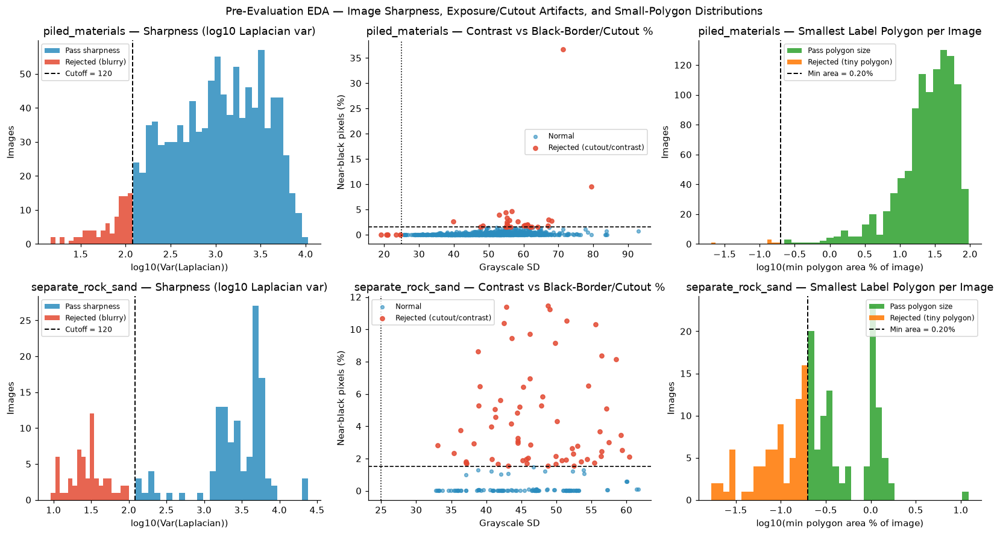

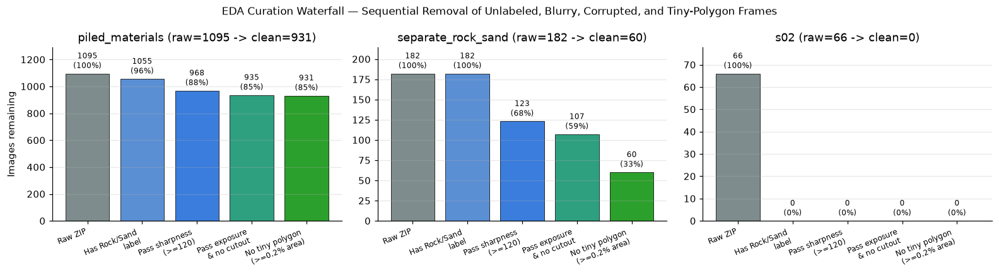

In [3]:
# ---------- 2. Paper Fig 1 & Fig 2: EDA Quality Distributions & Filtering Waterfall ----------
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for row, ds in enumerate(['piled_materials', 'separate_rock_sand']):
    df = EDA_DFS[ds]
    labeled = df[df.n_rel_labels > 0]

    # (a) Sharpness (log10 Laplacian variance)
    ax = axes[row, 0]
    vals = np.log10(np.clip(labeled.sharpness, 1.0, None))
    thr_log = np.log10(EDA_RULES['sharpness_min'])
    ax.hist(vals[labeled.sharpness >= EDA_RULES['sharpness_min']], bins=28, color='#2b8cbe', alpha=0.85, label='Pass sharpness')
    ax.hist(vals[labeled.sharpness < EDA_RULES['sharpness_min']], bins=18, color='#e34a33', alpha=0.85, label='Rejected (blurry)')
    ax.axvline(thr_log, color='k', ls='--', lw=1.3, label=f"Cutoff = {EDA_RULES['sharpness_min']:.0f}")
    ax.set_title(f"{ds} — Sharpness (log10 Laplacian var)")
    ax.set_xlabel('log10(Var(Laplacian))'); ax.set_ylabel('Images'); ax.legend(fontsize=8)

    # (b) Black cutout fraction vs contrast
    ax = axes[row, 1]
    bad_exp = (labeled.lum_std < EDA_RULES['lum_std_min']) | (labeled.black_frac > EDA_RULES['black_frac_max'])
    ax.scatter(labeled.lum_std[~bad_exp], 100*labeled.black_frac[~bad_exp], s=14, alpha=0.6, c='#2b8cbe', label='Normal')
    ax.scatter(labeled.lum_std[bad_exp], 100*labeled.black_frac[bad_exp], s=22, alpha=0.85, c='#e34a33', label='Rejected (cutout/contrast)')
    ax.axhline(100*EDA_RULES['black_frac_max'], color='k', ls='--', lw=1.1)
    ax.axvline(EDA_RULES['lum_std_min'], color='k', ls=':', lw=1.1)
    ax.set_title(f"{ds} — Contrast vs Black-Border/Cutout %")
    ax.set_xlabel('Grayscale SD'); ax.set_ylabel('Near-black pixels (%)'); ax.legend(fontsize=8)

    # (c) Minimum polygon area fraction per image (log10 %)
    ax = axes[row, 2]
    pfrac = np.log10(np.clip(100.0 * labeled.min_poly_frac, 1e-3, None))
    pthr = np.log10(100.0 * EDA_RULES['min_poly_area_frac'])
    ax.hist(pfrac[labeled.min_poly_frac >= EDA_RULES['min_poly_area_frac']], bins=26, color='#2ca02c', alpha=0.85, label='Pass polygon size')
    ax.hist(pfrac[labeled.min_poly_frac < EDA_RULES['min_poly_area_frac']], bins=16, color='#ff7f0e', alpha=0.9, label='Rejected (tiny polygon)')
    ax.axvline(pthr, color='k', ls='--', lw=1.3, label=f"Min area = {100*EDA_RULES['min_poly_area_frac']:.2f}%")
    ax.set_title(f"{ds} — Smallest Label Polygon per Image")
    ax.set_xlabel('log10(min polygon area % of image)'); ax.set_ylabel('Images'); ax.legend(fontsize=8)

fig.suptitle('Pre-Evaluation EDA — Image Sharpness, Exposure/Cutout Artifacts, and Small-Polygon Distributions', fontsize=12)
fig.tight_layout()
savefig('fig1_eda_quality_distributions')

# Waterfall funnel chart
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))
for ax, ds in zip(axes, ['piled_materials', 'separate_rock_sand', 's02']):
    df = EDA_DFS[ds]
    n0 = len(df)
    n1 = int((df.filter_stage != '1_no_relevant_label').sum())
    n2 = int((~df.filter_stage.isin(['1_no_relevant_label', '2_blurry_low_sharpness'])).sum())
    n3 = int((~df.filter_stage.isin(['1_no_relevant_label', '2_blurry_low_sharpness', '3_bad_exposure_or_cutout'])).sum())
    n4 = int(df.keep.sum())
    stages = ['Raw ZIP', 'Has Rock/Sand\nlabel', 'Pass sharpness\n(>=120)', 'Pass exposure\n& no cutout', 'No tiny polygon\n(>=0.2% area)']
    counts = [n0, n1, n2, n3, n4]
    cols = ['#7f8c8d', '#5b8fd4', '#3b7ddd', '#2ea080', '#2ca02c']
    bars = ax.bar(range(len(stages)), counts, color=cols, edgecolor='k', lw=0.5)
    for b, c in zip(bars, counts):
        ax.text(b.get_x() + b.get_width()/2, c + max(1, 0.02*n0), f'{c}\n({100*c/max(1,n0):.0f}%)',
                ha='center', va='bottom', fontsize=8)
    ax.set_xticks(range(len(stages))); ax.set_xticklabels(stages, rotation=22, ha='right', fontsize=8)
    ax.set_ylim(0, n0 * 1.18); ax.set_title(f'{ds} (raw={n0} -> clean={n4})'); ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Images remaining')
fig.suptitle('EDA Curation Waterfall — Sequential Removal of Unlabeled, Blurry, Corrupted, and Tiny-Polygon Frames', fontsize=11)
fig.tight_layout()
savefig('fig2_eda_curation_waterfall')

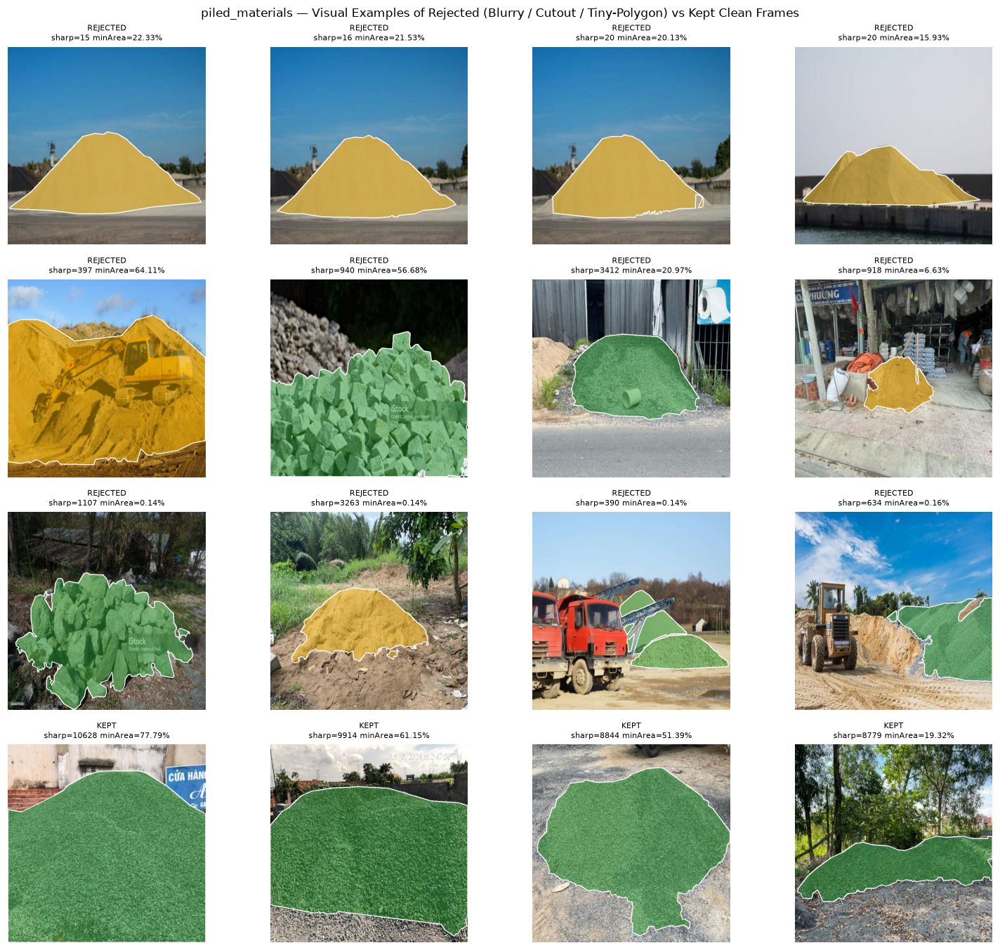

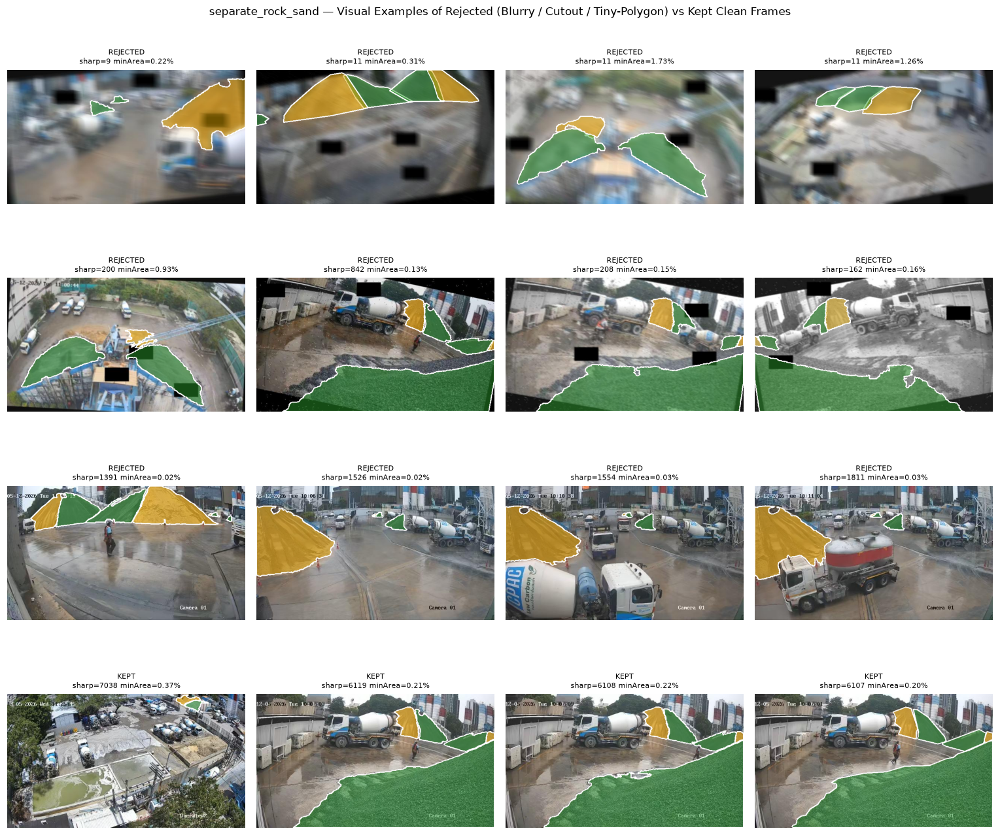

In [4]:
# ---------- 3. Paper Fig 3: Visual Audit Gallery of Rejected vs Kept Clean Images ----------
def draw_gt_overlay(r, names, ont):
    im = cv2.imread(r.image_path)
    rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    H, W = rgb.shape[:2]
    for c, pts in parse_seg_label(r.label_path):
        cid = ont.get(names[c]) if names and c < len(names) else None
        if cid is None:
            continue
        px = (pts * [W, H]).astype(np.int32)
        col = (44, 160, 44) if cid == 0 else (230, 171, 2)
        m = np.zeros((H, W), np.uint8)
        cv2.fillPoly(m, [px], 1)
        rgb[m.astype(bool)] = (0.52 * rgb[m.astype(bool)] + 0.48 * np.array(col)).astype(np.uint8)
        cv2.polylines(rgb, [px], True, (255, 255, 255), 2)
    return rgb

for ds in ['piled_materials', 'separate_rock_sand']:
    df = EDA_DFS[ds]
    names = YAML_NAMES[ds]
    ont = EXTERNAL_REVIEWS[ds]['ontology']
    cats = [
        ('2_blurry_low_sharpness', 'REJECTED: Blurry (low Laplacian var)'),
        ('3_bad_exposure_or_cutout', 'REJECTED: Cutout / Bad Exposure'),
        ('4_has_tiny_polygon', 'REJECTED: Tiny Label Polygon (<0.2%)'),
        ('5_keep_clean', 'KEPT: Clean Curated Cohort'),
    ]
    fig, axes = plt.subplots(4, 4, figsize=(14, 12.5))
    for r_idx, (st_code, title) in enumerate(cats):
        sub = df[df.filter_stage == st_code]
        if st_code == '2_blurry_low_sharpness':
            sub = sub.sort_values('sharpness')
        elif st_code == '4_has_tiny_polygon':
            sub = sub.sort_values('min_poly_frac')
        elif st_code == '5_keep_clean':
            sub = sub.sort_values('sharpness', ascending=False)
        picks = sub.head(4)
        for c_idx in range(4):
            ax = axes[r_idx, c_idx]
            if c_idx < len(picks):
                row = picks.iloc[c_idx]
                ax.imshow(draw_gt_overlay(row, names, ont))
                ax.set_title(f"{title.split(':')[0]}\nsharp={row.sharpness:.0f} minArea={100*row.min_poly_frac:.2f}%", fontsize=7.5)
            ax.axis('off')
    fig.suptitle(f'{ds} — Visual Examples of Rejected (Blurry / Cutout / Tiny-Polygon) vs Kept Clean Frames', fontsize=11)
    fig.tight_layout()
    savefig(f'fig3_eda_rejected_vs_kept_{ds}')

In [5]:
# ---------- 4. Model Registry (20 Frozen CV v2 Runs + Legacy 90% Models) & Evaluators ----------
import torch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as maskUtils
from ultralytics import YOLO

def all_eval_models():
    runs = []
    for d in sorted(RUNS.iterdir()):
        fz = d/'freeze.json'
        if not fz.exists():
            continue
        f = json.loads(fz.read_text())
        spec = f['identity']['spec']
        runs.append(dict(
            name=d.name,
            family=f"cv_v2_{spec['job']['recipe']['name']}",
            model=spec['job']['recipe']['name'],
            arm=spec['job']['arm'],
            fold=spec['job']['fold'],
            task='segment',
            ckpt=d/'selected.pt',
            thr={int(k): float(v) for k, v in f['thresholds'].items()},
        ))
    for lm in LEGACY_MODELS:
        if Path(lm['ckpt']).is_file():
            runs.append(dict(
                name=lm['name'],
                family=lm['name'],
                model=lm['model'],
                arm=lm['arm'],
                fold=0,
                task=lm['task'],
                ckpt=Path(lm['ckpt']),
                thr={0: float(lm['conf']), 1: float(lm['conf'])},
            ))
    return runs

def build_eval_dataframe(ds_name, clean_only=True):
    df = EDA_DFS[ds_name]
    names = YAML_NAMES[ds_name]
    ont = EXTERNAL_REVIEWS[ds_name]['ontology']
    sub = df[df.keep] if clean_only else df[df.n_rel_labels > 0]
    rows = []
    for r in sub.itertuples(index=False):
        polys = [(c, pts) for c, pts in parse_seg_label(r.label_path)
                 if names and c < len(names) and ont.get(names[c]) is not None]
        if not polys:
            continue
        rows.append(dict(stem=r.stem, w=r.w, h=r.h, image=Path(r.image_path),
                         names=names, polys=polys, sharpness=r.sharpness))
    return pd.DataFrame(rows)

def build_coco_gt(df, ont):
    images, anns, cats = [], [], set()
    aid = 0
    for i, r in enumerate(df.itertuples(index=False)):
        images.append(dict(id=i, file_name=r.stem, width=r.w, height=r.h))
        for c, pts in r.polys:
            cid = ont.get(r.names[c])
            if cid is None:
                continue
            cats.add(cid)
            xy = (pts * [r.w, r.h]).astype(np.float64).ravel().tolist()
            xs, ys = xy[0::2], xy[1::2]
            anns.append(dict(
                id=aid, image_id=i, category_id=cid,
                segmentation=[xy],
                bbox=[min(xs), min(ys), max(xs) - min(xs), max(ys) - min(ys)],
                area=float(cv2.contourArea(np.array(xy).reshape(-1, 1, 2).astype(np.float32))),
                iscrowd=0,
            ))
            aid += 1
    return dict(images=images, annotations=anns,
                categories=[dict(id=c, name=CLS[c]) for c in sorted(cats)])

def coco_eval_quiet(gt_json, preds, iou_type):
    if not preds:
        return dict(AP=0.0, AP50=0.0, AP75=0.0, AR=0.0)
    import io, contextlib
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO()
        gt.dataset = gt_json
        gt.createIndex()
        dt = gt.loadRes(preds)
        e = COCOeval(gt, dt, iou_type)
        e.evaluate()
        e.accumulate()
        e.summarize()
        s = e.stats
    return dict(AP=float(s[0]), AP50=float(s[1]), AP75=float(s[2]), AR=float(s[8]))

def box_iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    ua = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1]) + max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def evaluate_run_on_df(run, df, ont, gt_json):
    model = YOLO(str(run['ckpt']))
    thr = run['thr']
    is_seg = (run['task'] == 'segment')
    preds_seg, preds_box = [], []
    m_tp = m_fp = m_fn = 0
    b_tp = b_fp = b_fn = 0

    for i, r in enumerate(df.itertuples(index=False)):
        res = model.predict(str(r.image), imgsz=IMGSZ, conf=0.001, verbose=False)[0]
        gm_masks, gm_boxes, gc_ = [], [], []
        for c, pts in r.polys:
            cid = ont.get(r.names[c])
            if cid is None:
                continue
            px = (pts * [r.w, r.h]).astype(np.int32)
            g = np.zeros((r.h, r.w), np.uint8)
            cv2.fillPoly(g, [px], 1)
            gm_masks.append(g.astype(bool))
            x, y, w, h = cv2.boundingRect(px)
            gm_boxes.append((float(x), float(y), float(x + w), float(y + h)))
            gc_.append(cid)

        pm_masks, pm_boxes, pm_cls, pm_sc = [], [], [], []
        if res.boxes is not None and len(res.boxes):
            for k in range(len(res.boxes)):
                c = int(res.boxes.cls[k])
                s = float(res.boxes.conf[k])
                if s < thr.get(c, 0.25):
                    continue
                if is_seg and res.masks is not None and k < len(res.masks.data):
                    m = cv2.resize(res.masks.data[k].cpu().numpy(), (r.w, r.h)) > 0.5
                    if not m.any():
                        continue
                    rle = maskUtils.encode(np.asfortranarray(m.astype(np.uint8)))
                    rle['counts'] = rle['counts'].decode()
                    x, y, w, h = cv2.boundingRect(m.astype(np.uint8))
                    preds_seg.append(dict(image_id=i, category_id=c, score=s, segmentation=rle))
                    preds_box.append(dict(image_id=i, category_id=c, score=s, bbox=[float(x), float(y), float(w), float(h)]))
                    pm_masks.append(m)
                    pm_boxes.append((float(x), float(y), float(x + w), float(y + h)))
                    pm_cls.append(c); pm_sc.append(s)
                else:
                    x1, y1, x2, y2 = [float(v) for v in res.boxes.xyxy[k].cpu().numpy()]
                    preds_box.append(dict(image_id=i, category_id=c, score=s, bbox=[x1, y1, x2 - x1, y2 - y1]))
                    pm_boxes.append((x1, y1, x2, y2))
                    pm_cls.append(c); pm_sc.append(s)

        order = sorted(range(len(pm_sc)), key=lambda z: -pm_sc[z])
        # Box-level matching
        used_b = set()
        for idx in order:
            cands = [j for j in range(len(gm_boxes)) if j not in used_b and gc_[j] == pm_cls[idx]]
            ov = [box_iou(pm_boxes[idx], gm_boxes[j]) for j in cands]
            if ov and max(ov) >= IOU_T:
                used_b.add(cands[int(np.argmax(ov))]); b_tp += 1
            else:
                b_fp += 1
        b_fn += len(gm_boxes) - len(used_b)

        # Mask-level matching (only for segmentation models)
        if is_seg:
            used_m = set()
            for idx in order:
                cands = [j for j in range(len(gm_masks)) if j not in used_m and gc_[j] == pm_cls[idx]]
                ov = [float((pm_masks[idx] & gm_masks[j]).sum()) / max(1, float((pm_masks[idx] | gm_masks[j]).sum())) for j in cands]
                if ov and max(ov) >= IOU_T:
                    used_m.add(cands[int(np.argmax(ov))]); m_tp += 1
                else:
                    m_fp += 1
            m_fn += len(gm_masks) - len(used_m)

    ev_b = coco_eval_quiet(gt_json, preds_box, 'bbox')
    ev_s = coco_eval_quiet(gt_json, preds_seg, 'segm') if is_seg else dict(AP=np.nan, AP50=np.nan, AP75=np.nan, AR=np.nan)

    b_p = b_tp / max(1, b_tp + b_fp)
    b_r = b_tp / max(1, b_tp + b_fn)
    b_f1 = 2 * b_p * b_r / max(1e-9, b_p + b_r)

    if is_seg:
        m_p = m_tp / max(1, m_tp + m_fp)
        m_r = m_tp / max(1, m_tp + m_fn)
        m_f1 = 2 * m_p * m_r / max(1e-9, m_p + m_r)
    else:
        m_p = m_r = m_f1 = np.nan

    return dict(
        dataset='', cohort='', run=run['name'], model=run['model'], arm=run['arm'],
        fold=run['fold'], task=run['task'], n_images=len(df),
        mask_AP=ev_s['AP'], mask_AP50=ev_s['AP50'], mask_AP75=ev_s['AP75'],
        mask_tp=m_tp if is_seg else np.nan, mask_fp=m_fp if is_seg else np.nan, mask_fn=m_fn if is_seg else np.nan,
        mask_precision=m_p, mask_recall=m_r, mask_f1=m_f1,
        box_AP=ev_b['AP'], box_AP50=ev_b['AP50'], box_AP75=ev_b['AP75'],
        box_tp=b_tp, box_fp=b_fp, box_fn=b_fn,
        box_precision=b_p, box_recall=b_r, box_f1=b_f1,
    )

MODELS = all_eval_models()
print(f'Registered {len(MODELS)} models for evaluation (20 CV v2 runs + {len(MODELS)-20} legacy benchmarks):')
for m in MODELS[20:]:
    print('  legacy:', m['name'], '| task:', m['task'], '| ckpt:', m['ckpt'].name)

Registered 23 models for evaluation (20 CV v2 runs + 3 legacy benchmarks):
  legacy: bench_ws_yolo26s_seg | task: segment | ckpt: best.pt
  legacy: bench_ws_yolo26n_det | task: detect | ckpt: best.pt
  legacy: legacy_final_best_n_seg | task: segment | ckpt: best.pt


In [6]:
# ---------- 5. Run Evaluation on EDA-Curated Clean Cohort (and Raw Cohort for comparison) ----------
CLEAN_DFS, RAW_DFS = {}, {}
for ds in ['piled_materials', 'separate_rock_sand']:
    CLEAN_DFS[ds] = build_eval_dataframe(ds, clean_only=True)
    RAW_DFS[ds]   = build_eval_dataframe(ds, clean_only=False)
    print(f"{ds}: clean_cohort={len(CLEAN_DFS[ds])} imgs | raw_labeled_cohort={len(RAW_DFS[ds])} imgs")

RESULTS = []
# 5a. Evaluate ALL 23 models on the EDA-curated CLEAN cohort
for ds, df in CLEAN_DFS.items():
    ont = EXTERNAL_REVIEWS[ds]['ontology']
    gt_json = build_coco_gt(df, ont)
    for run in MODELS:
        row = evaluate_run_on_df(run, df, ont, gt_json)
        row['dataset'] = ds
        row['cohort'] = 'clean_curated'
        RESULTS.append(row)
        print(f"[CLEAN] {ds:18s} | {run['name']:40s} | maskAP50={row['mask_AP50'] if pd.notna(row['mask_AP50']) else -1:6.3f} "
              f"boxAP50={row['box_AP50']:6.3f} | box P={row['box_precision']:.3f} R={row['box_recall']:.3f} F1={row['box_f1']:.3f}")

# 5b. Evaluate representative models (fold0 CV pairs + legacy 90% models) on RAW unfiltered cohort to quantify EDA cleaning effect
REP_RUNS = [r for r in MODELS if r['fold'] == 0]
for ds, df in RAW_DFS.items():
    ont = EXTERNAL_REVIEWS[ds]['ontology']
    gt_json = build_coco_gt(df, ont)
    for run in REP_RUNS:
        row = evaluate_run_on_df(run, df, ont, gt_json)
        row['dataset'] = ds
        row['cohort'] = 'raw_unfiltered'
        RESULTS.append(row)

RES = pd.DataFrame(RESULTS)
RES.to_csv(OUT/'results_all.csv', index=False)
RES_CLEAN = RES[RES.cohort == 'clean_curated'].copy()
RES_CLEAN.to_csv(OUT/'results_clean_curated.csv', index=False)
print('Saved full results to', OUT/'results_clean_curated.csv')

piled_materials: clean_cohort=931 imgs | raw_labeled_cohort=1055 imgs
separate_rock_sand: clean_cohort=60 imgs | raw_labeled_cohort=182 imgs


[CLEAN] piled_materials    | yolo26n_seg_fold0_seed42_control         | maskAP50= 0.109 boxAP50= 0.097 | box P=0.155 R=0.239 F1=0.188


[CLEAN] piled_materials    | yolo26n_seg_fold0_seed42_offline_aug     | maskAP50= 0.100 boxAP50= 0.091 | box P=0.284 R=0.273 F1=0.279


[CLEAN] piled_materials    | yolo26n_seg_fold1_seed42_control         | maskAP50= 0.070 boxAP50= 0.050 | box P=0.110 R=0.275 F1=0.157


[CLEAN] piled_materials    | yolo26n_seg_fold1_seed42_offline_aug     | maskAP50= 0.048 boxAP50= 0.048 | box P=0.167 R=0.157 F1=0.162


...

[CLEAN] separate_rock_sand | yolo26s_seg_fold4_seed42_offline_aug     | maskAP50= 0.092 boxAP50= 0.092 | box P=0.400 R=0.138 F1=0.205


[CLEAN] separate_rock_sand | bench_ws_yolo26s_seg                     | maskAP50= 0.126 boxAP50= 0.126 | box P=0.628 R=0.133 F1=0.220


[CLEAN] separate_rock_sand | bench_ws_yolo26n_det                     | maskAP50=-1.000 boxAP50= 0.018 | box P=0.192 R=0.025 F1=0.044


[CLEAN] separate_rock_sand | legacy_final_best_n_seg                  | maskAP50= 0.459 boxAP50= 0.384 | box P=0.562 R=0.404 F1=0.470


Saved full results to /home/supawich/Desktop/Aggregate_Project/experiment/results/nb18_external/20261014T161900541872Z/results_clean_curated.csv


In [7]:
# ---------- 6. Summary Tables: Mask Metrics, Box Metrics, and TP/FP/FN + P/R/F1 ----------
SUMMARY = (RES_CLEAN.groupby(['dataset', 'model', 'arm', 'task'], as_index=False)
           .agg(
               runs=('fold', 'count'),
               n_images=('n_images', 'first'),
               mask_AP=('mask_AP', 'mean'), mask_AP_sd=('mask_AP', 'std'),
               mask_AP50=('mask_AP50', 'mean'), mask_AP50_sd=('mask_AP50', 'std'),
               mask_P=('mask_precision', 'mean'), mask_R=('mask_recall', 'mean'), mask_F1=('mask_f1', 'mean'),
               mask_TP=('mask_tp', 'mean'), mask_FP=('mask_fp', 'mean'), mask_FN=('mask_fn', 'mean'),
               box_AP=('box_AP', 'mean'), box_AP_sd=('box_AP', 'std'),
               box_AP50=('box_AP50', 'mean'), box_AP50_sd=('box_AP50', 'std'),
               box_P=('box_precision', 'mean'), box_R=('box_recall', 'mean'), box_F1=('box_f1', 'mean'),
               box_TP=('box_tp', 'mean'), box_FP=('box_fp', 'mean'), box_FN=('box_fn', 'mean'),
           ).round(4))
SUMMARY.to_csv(OUT/'summary_clean_curated.csv', index=False)
print('=== Curated Clean Cohort Summary (Mask + Box + Instance TP/FP/FN & P/R/F1) ===')
display(SUMMARY)

# Raw vs Clean impact comparison on fold0 + legacy runs
RAW_VS_CLEAN = (RES[RES.run.isin([r['name'] for r in REP_RUNS])]
                .pivot_table(index=['dataset', 'model', 'arm', 'task'], columns='cohort',
                             values=['mask_AP50', 'box_AP50', 'box_precision', 'box_recall', 'box_f1'])
                .round(4))
RAW_VS_CLEAN.to_csv(OUT/'raw_vs_clean_comparison.csv')
print('=== Impact of Pre-Evaluation EDA Curation (Raw Unfiltered vs Clean Curated) ===')
display(RAW_VS_CLEAN)

=== Curated Clean Cohort Summary (Mask + Box + Instance TP/FP/FN & P/R/F1) ===


,dataset,model,arm,task,runs,n_images,mask_AP,mask_AP_sd,mask_AP50,mask_AP50_sd,...,box_AP,box_AP_sd,box_AP50,box_AP50_sd,box_P,box_R,box_F1,box_TP,box_FP,box_FN
0,piled_materials,bench_ws_yolo26n_det,legacy_90pct,detect,1,931,NaN,NaN,NaN,NaN,...,0.0355,NaN,0.1378,NaN,0.3937,0.2296,0.2901,248.0,382.0,832.0
1,piled_materials,bench_ws_yolo26s_seg,legacy_90pct,segment,1,931,0.0315,NaN,0.0887,NaN,...,0.0269,NaN,0.0826,NaN,0.2393,0.2028,0.2195,219.0,696.0,861.0
2,piled_materials,legacy_final_best_n_seg,legacy_ref,segment,1,931,0.0154,NaN,0.0398,NaN,...,0.0145,NaN,0.0382,NaN,0.1344,0.1981,0.1602,214.0,1378.0,866.0
3,piled_materials,yolo26n_seg,control,segment,5,931,0.0157,0.0123,0.0488,0.0424,...,0.0137,0.0109,0.0395,0.0366,0.0937,0.1554,0.1133,167.8,1691.2,912.2
4,piled_materials,yolo26n_seg,offline_aug,segment,5,931,0.0339,0.0072,0.0901,0.0251,...,0.0304,0.0047,0.0838,0.0215,0.2017,0.2743,0.2270,296.2,1232.2,783.8
5,piled_materials,yolo26s_seg,control,segment,5,931,0.0079,0.0055,0.0236,0.0205,...,0.0056,0.0031,0.0166,0.0133,0.0495,0.1069,0.0658,115.4,2580.6,964.6
6,piled_materials,yolo26s_seg,offline_aug,segment,5,931,0.0270,0.0186,0.0766,0.0618,...,0.0223,0.0139,0.0618,0.0471,0.1110,0.2102,0.1399,227.0,2261.6,853.0
7,separate_rock_sand,bench_ws_yolo26n_det,legacy_90pct,detect,1,60,NaN,NaN,NaN,NaN,...,0.0182,NaN,0.0182,NaN,0.1923,0.0246,0.0437,5.0,21.0,198.0
8,separate_rock_sand,bench_ws_yolo26s_seg,legacy_90pct,segment,1,60,0.0648,NaN,0.1259,NaN,...,0.0517,NaN,0.1259,NaN,0.6279,0.1330,0.2195,27.0,16.0,176.0
9,separate_rock_sand,legacy_final_best_n_seg,legacy_ref,segment,1,60,0.2577,NaN,0.4595,NaN,...,0.1947,NaN,0.3842,NaN,0.5616,0.4039,0.4699,82.0,64.0,121.0


=== Impact of Pre-Evaluation EDA Curation (Raw Unfiltered vs Clean Curated) ===


box_AP50  \
cohort                                                          clean_curated   
dataset            model                   arm          task                    
piled_materials    bench_ws_yolo26n_det    legacy_90pct detect         0.1378   
                   bench_ws_yolo26s_seg    legacy_90pct segment        0.0826   
                   legacy_final_best_n_seg legacy_ref   segment        0.0382   
                   yolo26n_seg             control      segment        0.0966   
                                           offline_aug  segment        0.0913   
                   yolo26s_seg             control      segment        0.0101   
                                           offline_aug  segment        0.0627   
separate_rock_sand bench_ws_yolo26n_det    legacy_90pct detect         0.0182   
                   bench_ws_yolo26s_seg    legacy_90pct segment        0.1259   
                   legacy_final_best_n_seg legacy_ref   segment        0.3842   
                   yolo26n_seg             control      segment        0.1248   
                                           offline_aug  segment        0.1481   
                   yolo26s_seg             control      segment        0.1199   
                                           offline_aug  segment        0.1417   

                                                                                \
cohort                                                          raw_unfiltered   
dataset            model                   arm          task                     
piled_materials    bench_ws_yolo26n_det    legacy_90pct detect          0.1412   
                   bench_ws_yolo26s_seg    legacy_90pct segment         0.0874   
                   legacy_final_best_n_seg legacy_ref   segment         0.0408   
                   yolo26n_seg             control      segment         0.1082   
                                           offline_aug  segment         0.0936   
                   yolo26s_seg             control      segment         0.0107   
                                           offline_aug  segment         0.0670   
separate_rock_sand bench_ws_yolo26n_det    legacy_90pct detect          0.0064   
                   bench_ws_yolo26s_seg    legacy_90pct segment         0.0682   
                   legacy_final_best_n_seg legacy_ref   segment         0.2133   
                   yolo26n_seg             control      segment         0.1049   
                                           offline_aug  segment         0.0960   
                   yolo26s_seg             control      segment         0.0769   
                                           offline_aug  segment         0.0764   

                                                                       box_f1  \
cohort                                                          clean_curated   
dataset            model                   arm          task                    
piled_materials    bench_ws_yolo26n_det    legacy_90pct detect         0.2901   
                   bench_ws_yolo26s_seg    legacy_90pct segment        0.2195   
                   legacy_final_best_n_seg legacy_ref   segment        0.1602   
                   yolo26n_seg             control      segment        0.1880   
                                           offline_aug  segment        0.2787   
                   yolo26s_seg             control      segment        0.0554   
                                           offline_aug  segment        0.1497   
separate_rock_sand bench_ws_yolo26n_det    legacy_90pct detect         0.0437   
                   bench_ws_yolo26s_seg    legacy_90pct segment        0.2195   
                   legacy_final_best_n_seg legacy_ref   segment        0.4699   
                   yolo26n_seg             control      segment        0.2463   
                                           offline_aug  segment        0.3030   
                   yolo26s_seg             control      segment        0.1865   


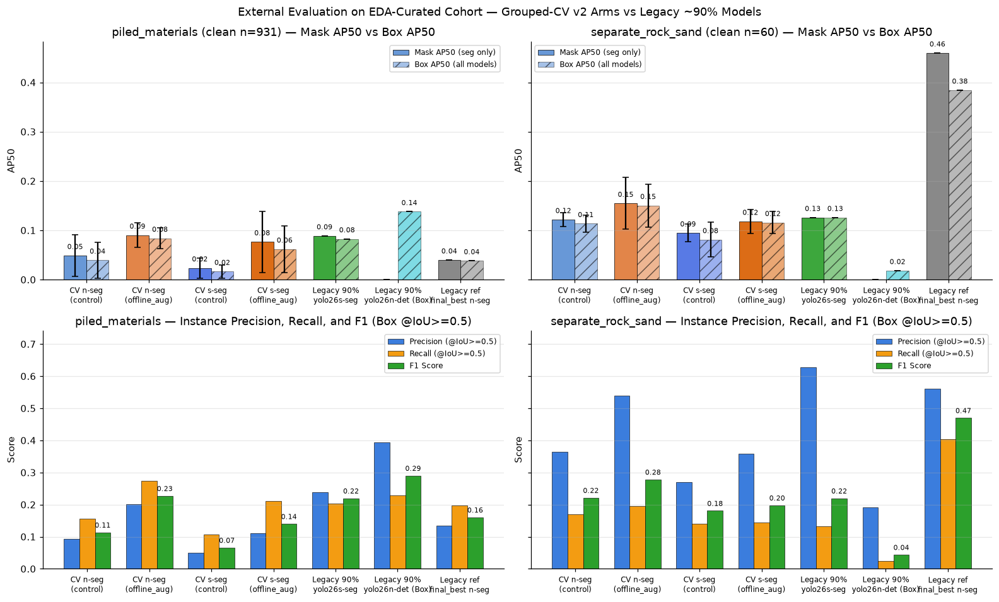

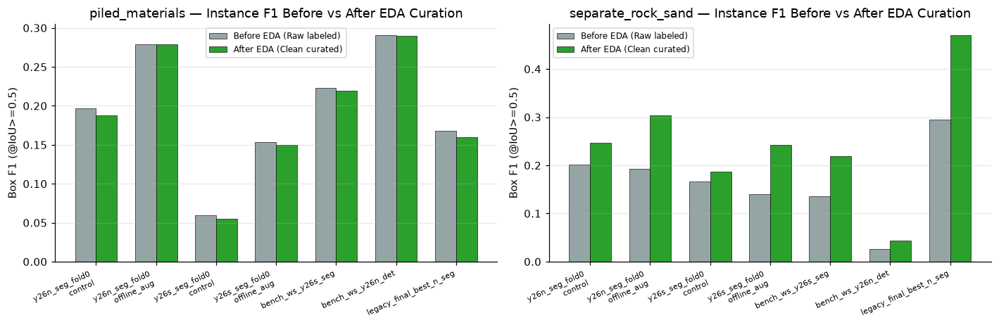

In [8]:
# ---------- 7. Paper Fig 4 & Fig 5: Clean Cohort AP50 (Mask & Box) + Precision/Recall/F1 ----------
ORDER_GROUPS = [
    ('yolo26n_seg', 'control',      'CV n-seg\n(control)',   '#5b8fd4'),
    ('yolo26n_seg', 'offline_aug',  'CV n-seg\n(offline_aug)', '#e07b39'),
    ('yolo26s_seg', 'control',      'CV s-seg\n(control)',   '#4a6fe3'),
    ('yolo26s_seg', 'offline_aug',  'CV s-seg\n(offline_aug)', '#d95f02'),
    ('bench_ws_yolo26s_seg', 'legacy_90pct', 'Legacy 90%\nyolo26s-seg', '#2ca02c'),
    ('bench_ws_yolo26n_det', 'legacy_90pct', 'Legacy 90%\nyolo26n-det (Box)', '#17becf'),
    ('legacy_final_best_n_seg', 'legacy_ref', 'Legacy ref\nfinal_best n-seg', '#7f7f7f'),
]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 8.8), sharey='row')
for col_i, ds in enumerate(['piled_materials', 'separate_rock_sand']):
    sub = SUMMARY[SUMMARY.dataset == ds]
    labels, m_ap50, m_sd, b_ap50, b_sd, cols = [], [], [], [], [], []
    b_p, b_r, b_f1 = [], [], []
    for mdl, arm, lbl, c in ORDER_GROUPS:
        r = sub[(sub.model == mdl) & (sub.arm == arm)]
        if r.empty:
            continue
        row = r.iloc[0]
        labels.append(lbl); cols.append(c)
        m_ap50.append(0.0 if pd.isna(row.mask_AP50) else float(row.mask_AP50))
        m_sd.append(0.0 if pd.isna(row.mask_AP50_sd) else float(row.mask_AP50_sd))
        b_ap50.append(float(row.box_AP50))
        b_sd.append(0.0 if pd.isna(row.box_AP50_sd) else float(row.box_AP50_sd))
        b_p.append(float(row.box_P)); b_r.append(float(row.box_R)); b_f1.append(float(row.box_F1))

    x = np.arange(len(labels)); w = 0.36
    ax = axes[0, col_i]
    ax.bar(x - w/2, m_ap50, w, yerr=m_sd, capsize=3, color=cols, alpha=0.92, edgecolor='k', lw=0.5, label='Mask AP50 (seg only)')
    ax.bar(x + w/2, b_ap50, w, yerr=b_sd, capsize=3, color=cols, alpha=0.55, edgecolor='k', lw=0.5, hatch='//', label='Box AP50 (all models)')
    for xi, (mv, bv) in enumerate(zip(m_ap50, b_ap50)):
        if mv > 0:
            ax.text(xi - w/2, mv + 0.01, f'{mv:.2f}', ha='center', va='bottom', fontsize=7)
        ax.text(xi + w/2, bv + 0.01, f'{bv:.2f}', ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(f"{ds} (clean n={int(sub.n_images.iloc[0])}) — Mask AP50 vs Box AP50")
    ax.set_ylabel('AP50'); ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8)

    ax2 = axes[1, col_i]
    w3 = 0.25
    ax2.bar(x - w3, b_p,  w3, color='#3b7ddd', edgecolor='k', lw=0.4, label='Precision (@IoU>=0.5)')
    ax2.bar(x,      b_r,  w3, color='#f39c12', edgecolor='k', lw=0.4, label='Recall (@IoU>=0.5)')
    ax2.bar(x + w3, b_f1, w3, color='#2ca02c', edgecolor='k', lw=0.4, label='F1 Score')
    for xi, fv in enumerate(b_f1):
        ax2.text(xi + w3, fv + 0.01, f'{fv:.2f}', ha='center', va='bottom', fontsize=7)
    ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=8)
    ax2.set_title(f"{ds} — Instance Precision, Recall, and F1 (Box @IoU>=0.5)")
    ax2.set_ylabel('Score'); ax2.set_ylim(0, max(0.65, max(b_p + b_r + b_f1) * 1.18))
    ax2.grid(axis='y', alpha=0.3); ax2.legend(fontsize=8)

fig.suptitle('External Evaluation on EDA-Curated Cohort — Grouped-CV v2 Arms vs Legacy ~90% Models', fontsize=12)
fig.tight_layout()
savefig('fig4_clean_ap50_and_prf1_comparison')

# Fig 5: Raw vs Clean Curated AP50 & F1 improvement
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, ds in zip(axes, ['piled_materials', 'separate_rock_sand']):
    sub = RES[(RES.dataset == ds) & (RES.run.isin([r['name'] for r in REP_RUNS]))]
    piv = sub.pivot(index='run', columns='cohort', values='box_f1').reindex([r['name'] for r in REP_RUNS])
    x = np.arange(len(piv)); w = 0.35
    ax.bar(x - w/2, piv['raw_unfiltered'], w, color='#95a5a6', edgecolor='k', lw=0.4, label='Before EDA (Raw labeled)')
    ax.bar(x + w/2, piv['clean_curated'],  w, color='#2ca02c', edgecolor='k', lw=0.4, label='After EDA (Clean curated)')
    ax.set_xticks(x)
    ax.set_xticklabels([r.replace('_seed42_', '\n').replace('yolo26', 'y26') for r in piv.index], rotation=25, ha='right', fontsize=7.5)
    ax.set_title(f'{ds} — Instance F1 Before vs After EDA Curation')
    ax.set_ylabel('Box F1 (@IoU>=0.5)'); ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
savefig('fig5_raw_vs_clean_f1_impact')

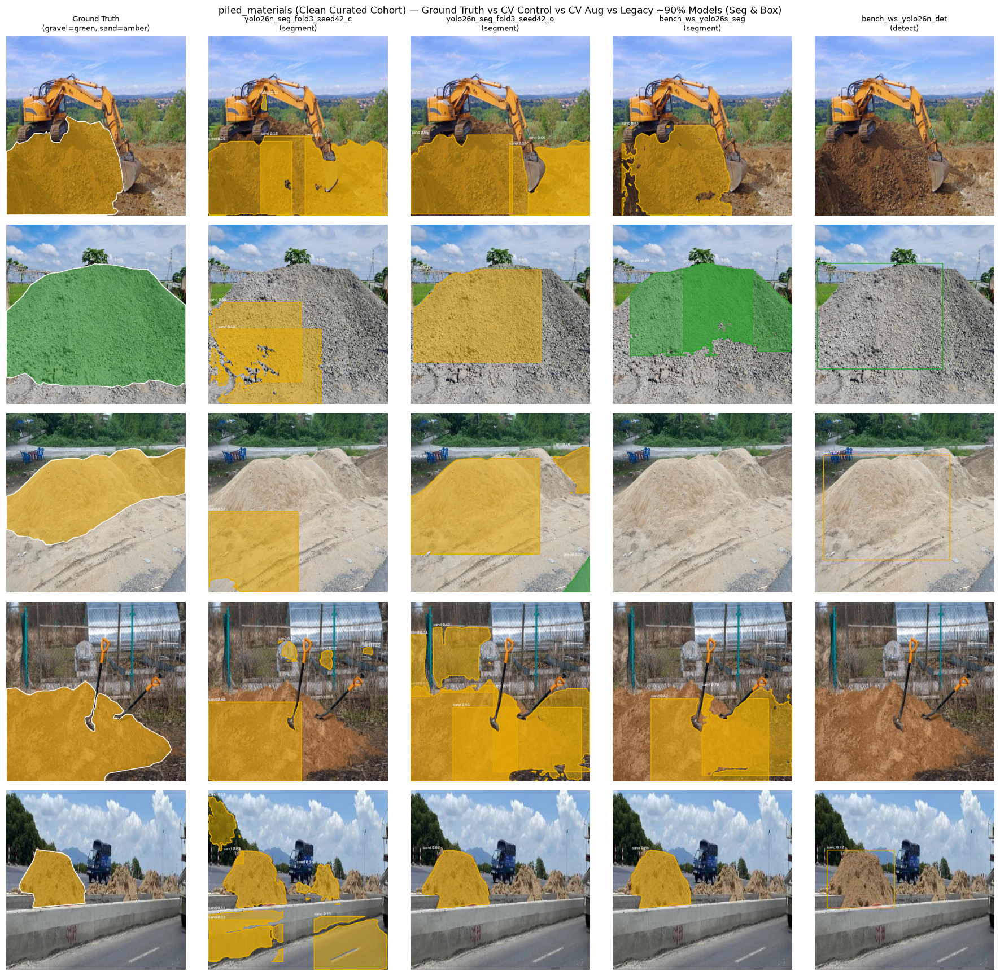

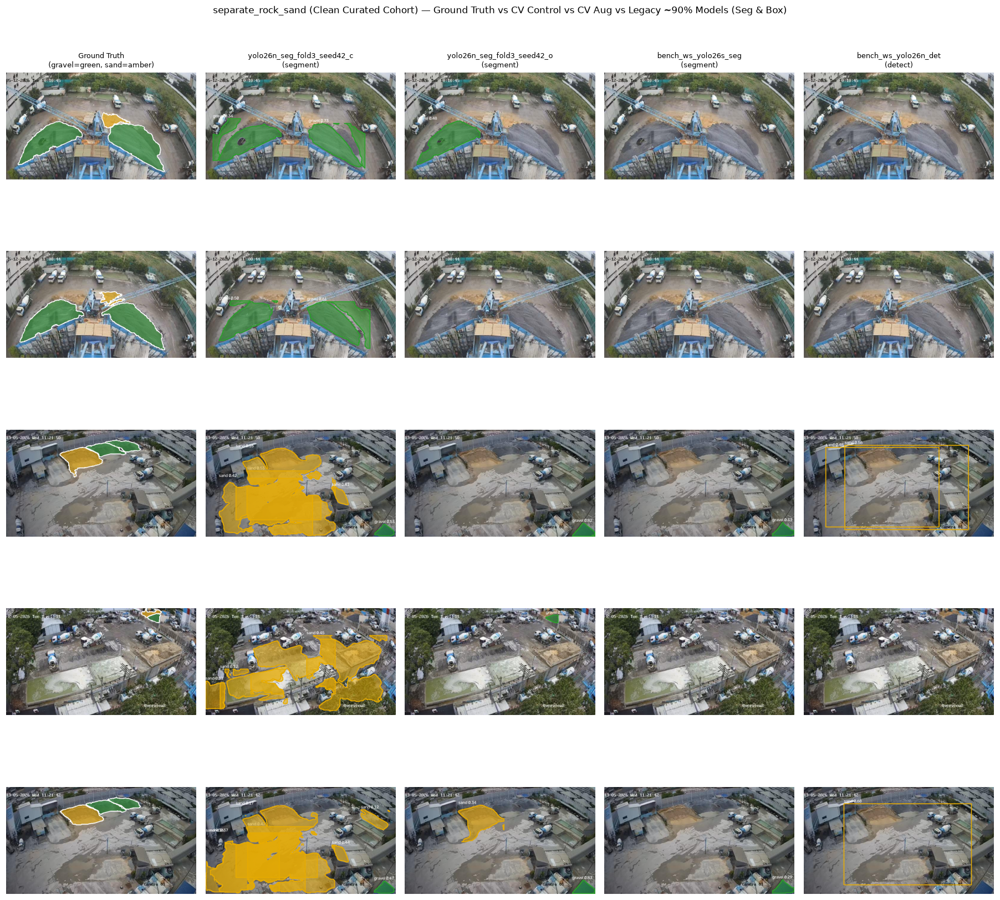

In [9]:
# ---------- 8. Paper Fig 6 & Fig 7: Multi-Model Qualitative Panels & FP/FN Diagnostic Gallery ----------
def render_prediction(im_rgb, res, task, thr):
    H, W = im_rgb.shape[:2]
    out = im_rgb.copy()
    if res.boxes is None or len(res.boxes) == 0:
        return out
    for k in range(len(res.boxes)):
        c = int(res.boxes.cls[k]); s = float(res.boxes.conf[k])
        if s < thr.get(c, 0.25):
            continue
        col = (44, 160, 44) if c == 0 else (230, 171, 2)
        if task == 'segment' and res.masks is not None and k < len(res.masks.data):
            m = cv2.resize(res.masks.data[k].cpu().numpy(), (W, H)) > 0.5
            if not m.any():
                continue
            out[m] = (0.48 * out[m] + 0.52 * np.array(col)).astype(np.uint8)
            cnt, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(out, cnt, -1, col, 2)
            ys, xs = np.where(m)
            tx, ty = int(xs.min()), max(14, int(ys.min()) - 4)
        else:
            x1, y1, x2, y2 = [int(v) for v in res.boxes.xyxy[k].cpu().numpy()]
            cv2.rectangle(out, (x1, y1), (x2, y2), col, 2)
            tx, ty = x1, max(14, y1 - 4)
        cv2.putText(out, f'{CLS[c]} {s:.2f}', (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (255, 255, 255), 1, cv2.LINE_AA)
    return out

COMPARE_MODELS = [
    [r for r in MODELS if r['name'] == 'yolo26n_seg_fold3_seed42_control'][0],
    [r for r in MODELS if r['name'] == 'yolo26n_seg_fold3_seed42_offline_aug'][0],
    [r for r in MODELS if r['name'] == 'bench_ws_yolo26s_seg'][0],
    [r for r in MODELS if r['name'] == 'bench_ws_yolo26n_det'][0],
]
LOADED_COMPARE = [(m, YOLO(str(m['ckpt']))) for m in COMPARE_MODELS]

for ds in ['piled_materials', 'separate_rock_sand']:
    df = CLEAN_DFS[ds]
    ont = EXTERNAL_REVIEWS[ds]['ontology']
    picks = df.iloc[np.linspace(0, len(df) - 1, min(5, len(df))).astype(int)]
    fig, axes = plt.subplots(len(picks), 5, figsize=(16.5, 3.2 * len(picks)))
    for row_i, r in enumerate(picks.itertuples(index=False)):
        im_bgr = cv2.imread(str(r.image))
        im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
        # GT
        gt_vis = im_rgb.copy()
        for c, pts in r.polys:
            cid = ont.get(r.names[c])
            if cid is None:
                continue
            px = (pts * [r.w, r.h]).astype(np.int32)
            col = (44, 160, 44) if cid == 0 else (230, 171, 2)
            m = np.zeros((r.h, r.w), np.uint8); cv2.fillPoly(m, [px], 1)
            gt_vis[m.astype(bool)] = (0.48 * gt_vis[m.astype(bool)] + 0.52 * np.array(col)).astype(np.uint8)
            cv2.polylines(gt_vis, [px], True, (255, 255, 255), 2)
        axes[row_i, 0].imshow(gt_vis); axes[row_i, 0].axis('off')
        if row_i == 0:
            axes[row_i, 0].set_title('Ground Truth\n(gravel=green, sand=amber)', fontsize=8.5)
        for col_j, (m_info, y_mdl) in enumerate(LOADED_COMPARE, start=1):
            res = y_mdl.predict(str(r.image), imgsz=IMGSZ, conf=0.001, verbose=False)[0]
            vis = render_prediction(im_rgb, res, m_info['task'], m_info['thr'])
            axes[row_i, col_j].imshow(vis); axes[row_i, col_j].axis('off')
            if row_i == 0:
                axes[row_i, col_j].set_title(f"{m_info['name'][:26]}\n({m_info['task']})", fontsize=8.5)
    fig.suptitle(f'{ds} (Clean Curated Cohort) — Ground Truth vs CV Control vs CV Aug vs Legacy ~90% Models (Seg & Box)', fontsize=11)
    fig.tight_layout()
    savefig(f'fig6_qualitative_comparison_{ds}')